### EEG reconstruction analysis
Compare the reconstruction results for the F3 electrode across linear interpolation, cubic spline interpolation, inverse distance weighting (IDW), and spherical spline interpolation.

This notebook reads existing metric CSV files and previously saved reconstructed signals. It does not perform EEG interpolation. The signal caches must be generated once by running the updated individual method notebooks. Keep Processed_data outside the public GitHub repository (or ignore it using .gitignore).

The analyses include subject-level metric comparisons, power spectral density (PSD), spectral coherence, amplitude histograms, and a log–log PSD slope estimate.

In [4]:
from pathlib import Path
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import coherence, welch
from scipy.stats import linregress, norm
from IPython.display import display

In [19]:
# Point to the project directory containing Processed_data.
# Locate the directory containing processed EEG data.
current_dir = Path.cwd()

if current_dir.name.lower() == "processed_data":
    processed_dir = current_dir
else:
    processed_dir = current_dir / "Processed_data"

project_dir = processed_dir.parent

print("Processed data directory:", processed_dir.resolve())

cache_dir = processed_dir / "Reconstructed_signals"
analysis_dir = project_dir / "Analysis_results"
analysis_dir.mkdir(parents=True, exist_ok=True)

subjects = [f"sub-{number:03d}" for number in range(37, 66)]
psd_subject = "sub-059"
histogram_subject = "sub-059"
power_law_subject = "sub-059"
max_samples = 50000
random_state = 42
nperseg = 1024

# Set this to True to show separate histogram grids for all subjects and methods.
plot_all_histogram_grids = True

method_names = {
    "original": "Recorded F3",
    "linear": "Linear interpolation",
    "cubic": "Cubic spline",
    "idw": "IDW",
    "spherical": "Spherical spline",
}

metric_files = {
    "linear": "F3_linear_spatial_interpolation_metrics_all_subjects.csv",
    "cubic": "F3_cubic_spline_interpolation_metrics_all_subjects.csv",
    "idw": "F3_IDW_interpolation_metrics_all_subjects.csv",
    "spherical": "F3_spherical_spline_metrics_all_subjects.csv",
}

metric_columns = [
    "Pearsono koreliacija",
    "RMSE",
    "Abipusė informacija",
    "Vidutinė spektrinė koherencija",
    "Jensen-Shannon atstumas",
    "Jensen-Shannon divergencija",
]

Processed data directory: C:\Users\gytis\Baigiamasis\Processed_data


### Compare saved reconstruction metrics
Each interpolation notebook saves one CSV with subject-level evaluation metrics. This section works without the signal caches and can be run as soon as those CSV files exist. CSV field names are left unchanged to remain compatible with the original analysis.

In [20]:
def read_method_metrics(method, filename):
    """Read successful subject-level results for one interpolation method."""
    path = processed_dir / filename
    if not path.exists():
        print(f"Metrics not found for {method_names[method]}: {path}")
        return None

    frame = pd.read_csv(path)
    if "subjektas" not in frame.columns:
        raise ValueError(f"Missing 'subjektas' column in {path.name}")

    if "statusas" in frame.columns:
        frame = frame.loc[frame["statusas"] == "ok"].copy()

    frame["method"] = method
    frame["method_name"] = method_names[method]
    for metric in metric_columns:
        if metric in frame.columns:
            frame[metric] = pd.to_numeric(frame[metric], errors="coerce")
    return frame


metric_frames = [
    frame
    for method, filename in metric_files.items()
    if (frame := read_method_metrics(method, filename)) is not None
]

if metric_frames:
    metrics_df = pd.concat(metric_frames, ignore_index=True)
    metrics_df = metrics_df.drop_duplicates(["subjektas", "method"], keep="last")
    valid_metrics = [column for column in metric_columns if column in metrics_df.columns]
    if not valid_metrics:
        raise ValueError("None of the expected metric columns were found in the CSV files.")

    metrics_summary = metrics_df.groupby("method_name", sort=False)[valid_metrics].agg(
        ["count", "mean", "std"]
    )
    display(metrics_summary)
    metrics_df.to_csv(analysis_dir / "F3_all_methods_metrics.csv", index=False, encoding="utf-8-sig")
    metrics_summary.to_csv(analysis_dir / "F3_methods_summary.csv", encoding="utf-8-sig")
else:
    metrics_df = pd.DataFrame()
    metrics_summary = pd.DataFrame()
    valid_metrics = []
    print("No metric CSV files found. Run the four interpolation notebooks first.")

Pearsono koreliacija                      RMSE            \
                                    count      mean       std count      mean   
method_name                                                                     
Linear interpolation                   29  0.614647  0.189081    29  0.000005   
Cubic spline                           29  0.619139  0.195589    29  0.000005   
IDW                                    29  0.698824  0.201251    29  0.000005   
Spherical spline                       29  0.687055  0.233594    29  0.000005   

                               Abipusė informacija                      \
                           std               count      mean       std   
method_name                                                              
Linear interpolation  0.000002                  29  0.352950  0.200298   
Cubic spline          0.000002                  29  0.358427  0.194116   
IDW                   0.000002                  29  0.508852  0.227896   
Spherical spline      0.000003                  29  0.512357  0.214955   

                     Vidutinė spektrinė koherencija                      \
                                              count      mean       std   
method_name                                                               
Linear interpolation                             29  0.314327  0.156904   
Cubic spline                                     29  0.318688  0.156740   
IDW                                              29  0.456520  0.171323   
Spherical spline                                 29  0.481599  0.165780   

                     Jensen-Shannon atstumas                      \
                                       count      mean       std   
method_name                                                        
Linear interpolation                      29  0.113294  0.046531   
Cubic spline                              29  0.114610  0.048181   
IDW                                       29  0.134720  0.070538   
Spherical spline                          29  0.131851  0.068556   

                     Jensen-Shannon divergencija                      
                                           count      mean       std  
method_name                                                           
Linear interpolation                          29  0.014926  0.013463  
Cubic spline                                  29  0.015377  0.013910  
IDW                                           29  0.022953  0.025818  
Spherical spline                              29  0.021922  0.023313

In [21]:
if not metrics_df.empty:
    common_subjects = set(subjects)
    for method in metric_files:
        available = set(metrics_df.loc[metrics_df["method"] == method, "subjektas"])
        common_subjects &= available
    common_subjects = sorted(common_subjects)
    print(f"Subjects with successful results for all four methods: {len(common_subjects)}")

    if common_subjects:
        comparison = metrics_df.loc[metrics_df["subjektas"].isin(common_subjects)].copy()
        common_summary = comparison.groupby("method_name", sort=False)[valid_metrics].mean()
        display(common_summary)
    else:
        print("No common subjects for a paired comparison.")

Subjects with successful results for all four methods: 29


,Pearsono koreliacija,RMSE,Abipusė informacija,Vidutinė spektrinė koherencija,Jensen-Shannon atstumas,Jensen-Shannon divergencija
method_name,,,,,,
Linear interpolation,0.614647,0.000005,0.352950,0.314327,0.113294,0.014926
Cubic spline,0.619139,0.000005,0.358427,0.318688,0.114610,0.015377
IDW,0.698824,0.000005,0.508852,0.456520,0.134720,0.022953
Spherical spline,0.687055,0.000005,0.512357,0.481599,0.131851,0.021922


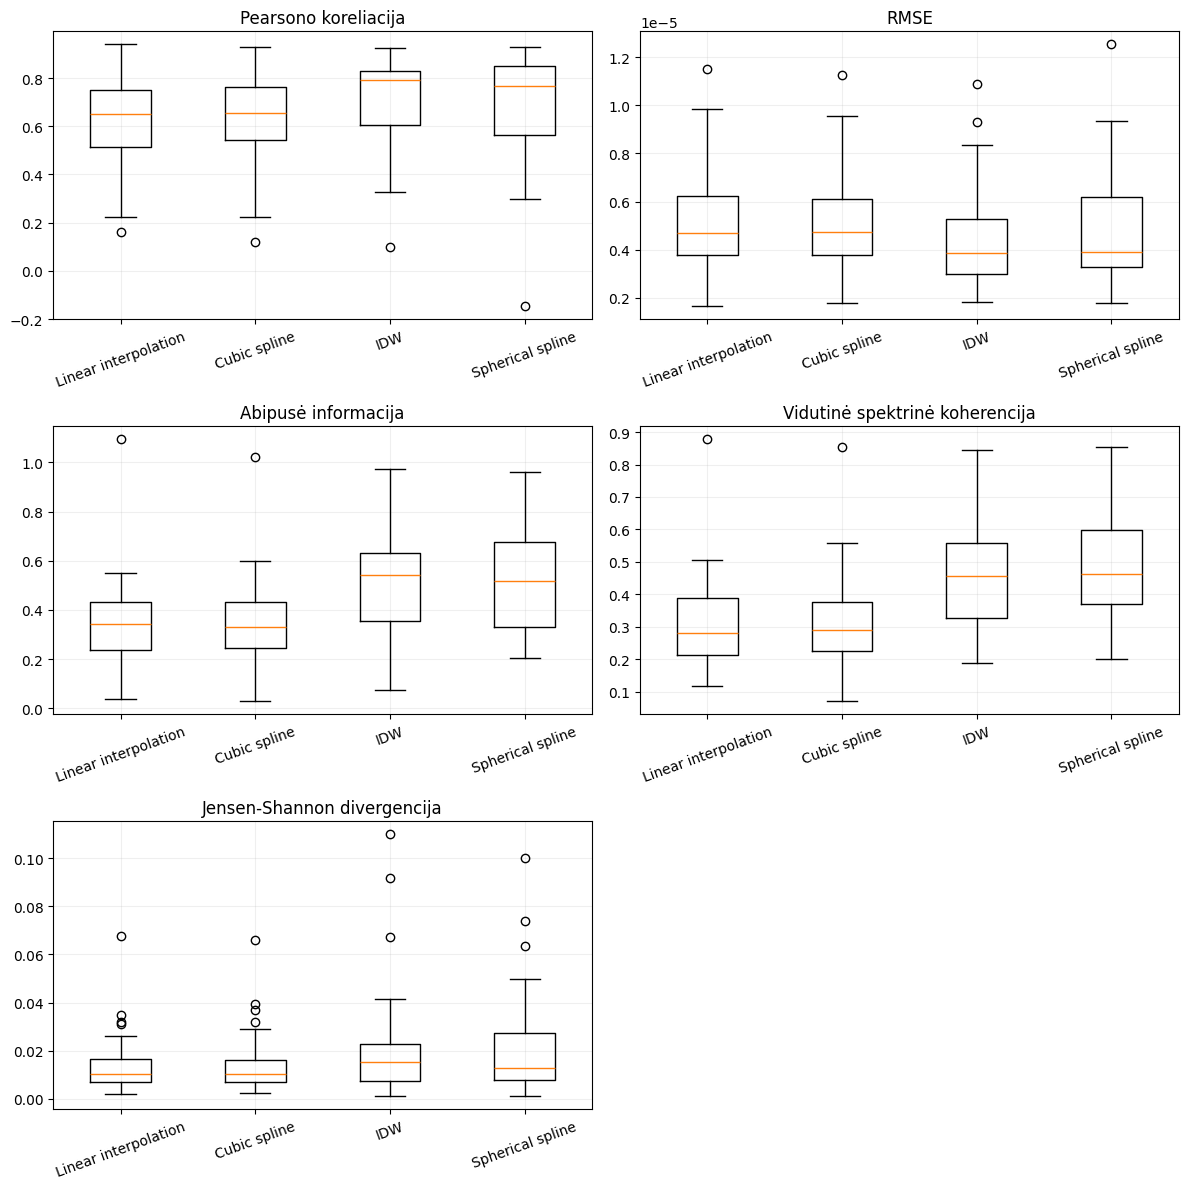

In [22]:
# Compare the subject-level distributions of the recorded metrics.
if not metrics_df.empty:
    shown_metrics = [
        "Pearsono koreliacija", "RMSE", "Abipusė informacija",
        "Vidutinė spektrinė koherencija", "Jensen-Shannon divergencija",
    ]
    shown_metrics = [metric for metric in shown_metrics if metric in valid_metrics]
    if shown_metrics:
        fig, axes = plt.subplots(ceil(len(shown_metrics) / 2), 2, figsize=(12, 4 * ceil(len(shown_metrics) / 2)))
        axes = np.array(axes).ravel()
        for ax, metric in zip(axes, shown_metrics):
            values = [
                metrics_df.loc[metrics_df["method"] == method, metric].dropna().values
                for method in metric_files
            ]
            if any(len(v) for v in values):
                ax.boxplot(values, tick_labels=[method_names[method] for method in metric_files])
                ax.tick_params(axis="x", rotation=20)
            ax.set_title(metric)
            ax.grid(alpha=0.2)
        for ax in axes[len(shown_metrics):]:
            ax.axis("off")
        fig.tight_layout()
        plt.show()

### Load saved EEG signals
Each method notebook creates a compressed .npz file for every subject in Processed_data/Reconstructed_signals. The original F3 signal is saved separately as well. If these files are missing, rerun the updated method notebooks once to generate them; future runs of this analysis will only read the saved files.

In [23]:
def cache_path(subject_code, method):
    return cache_dir / f"{subject_code}_{method}.npz"


def subject_has_all_signals(subject_code):
    return all(cache_path(subject_code, method).exists() for method in method_names)


def load_subject_signals(subject_code):
    """Load recorded and interpolated F3 signals without recomputing them."""
    missing = [method for method in method_names if not cache_path(subject_code, method).exists()]
    if missing:
        names = ", ".join(missing)
        raise FileNotFoundError(f"Missing saved signals for {subject_code}: {names}. Run the updated method notebooks once.")

    signals = {}
    sample_rates = []
    for method in method_names:
        with np.load(cache_path(subject_code, method), allow_pickle=False) as saved:
            signal = np.asarray(saved["signal"], dtype=float).ravel()
            sample_rates.append(float(saved["fs"]))
        if not np.isfinite(signal).all():
            raise ValueError(f"Non-finite values found in {subject_code}, method {method}")
        signals[method] = signal

    lengths = {len(signal) for signal in signals.values()}
    if len(lengths) != 1 or len(set(np.round(sample_rates, 8))) != 1:
        raise ValueError(f"Signals have different lengths or sampling rates for {subject_code}")
    return signals, sample_rates[0]


available_subjects = [subject for subject in subjects if subject_has_all_signals(subject)]
print(f"Saved signal sets available: {len(available_subjects)}/{len(subjects)} subjects")
if not available_subjects:
    print("Signal-based plots need the .npz files saved by the updated method notebooks.")

Saved signal sets available: 29/29 subjects


### Power spectral density (PSD)
Compare the recorded F3 signal with four reconstructed versions for a selected subject. PSD is estimated using Welch's method, as in the original notebook.

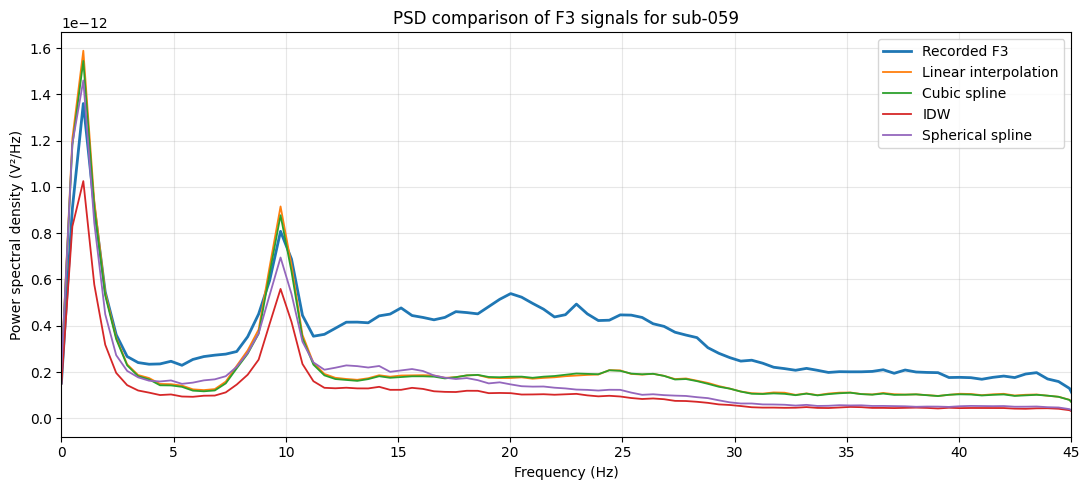

In [24]:
def plot_psd_comparison(subject_code):
    """Plot the 0–45 Hz PSD of all five signals for one subject."""
    signals, fs = load_subject_signals(subject_code)
    plt.figure(figsize=(11, 5))
    for method, signal in signals.items():
        frequencies, psd = welch(signal, fs=fs, nperseg=nperseg)
        plt.plot(frequencies, psd, label=method_names[method], linewidth=2 if method == "original" else 1.3)
    plt.xlim(0, 45)
    plt.title(f"PSD comparison of F3 signals for {subject_code}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density (V²/Hz)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


if subject_has_all_signals(psd_subject):
    plot_psd_comparison(psd_subject)
else:
    print(f"Skipping PSD comparison: signal caches for {psd_subject} are incomplete.")

### Spectral coherence
The original metric files include mean spectral coherence over 1–45 Hz. This visualization shows how coherence changes with frequency for the selected subject.

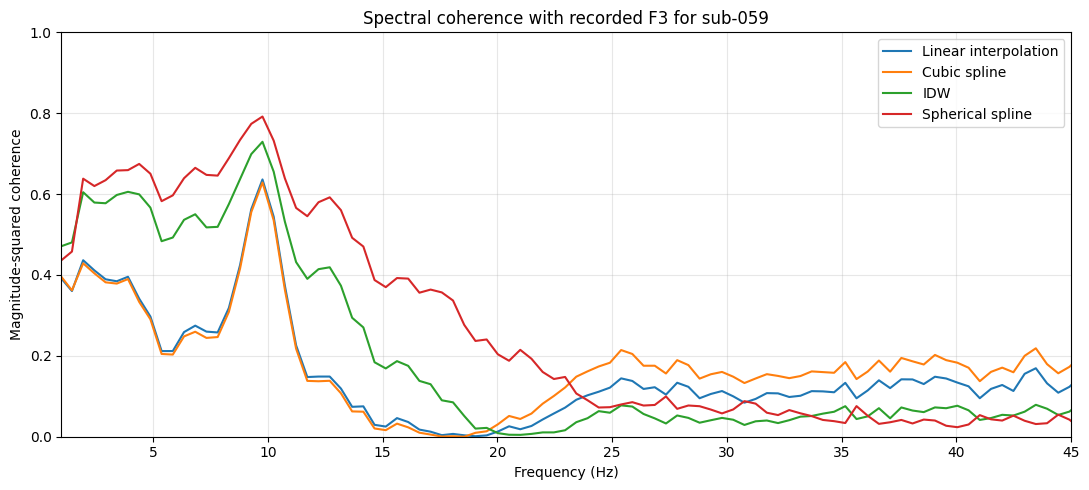

In [25]:
def plot_coherence_comparison(subject_code):
    """Compare frequency-dependent coherence with the recorded F3 channel."""
    signals, fs = load_subject_signals(subject_code)
    original = signals["original"]
    plt.figure(figsize=(11, 5))
    for method in metric_files:
        frequencies, values = coherence(original, signals[method], fs=fs, nperseg=nperseg)
        plt.plot(frequencies, values, label=method_names[method])
    plt.xlim(1, 45)
    plt.ylim(0, 1)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude-squared coherence")
    plt.title(f"Spectral coherence with recorded F3 for {subject_code}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


if subject_has_all_signals(psd_subject):
    plot_coherence_comparison(psd_subject)
else:
    print(f"Skipping coherence plot: signal caches for {psd_subject} are incomplete.")

### Amplitude histograms
Compare amplitude distributions visually using histograms and overlaid normal density curves for one selected subject. The curves are visual references, not evidence that the signals follow a normal distribution. Optionally generate histogram grids for all subjects and methods.

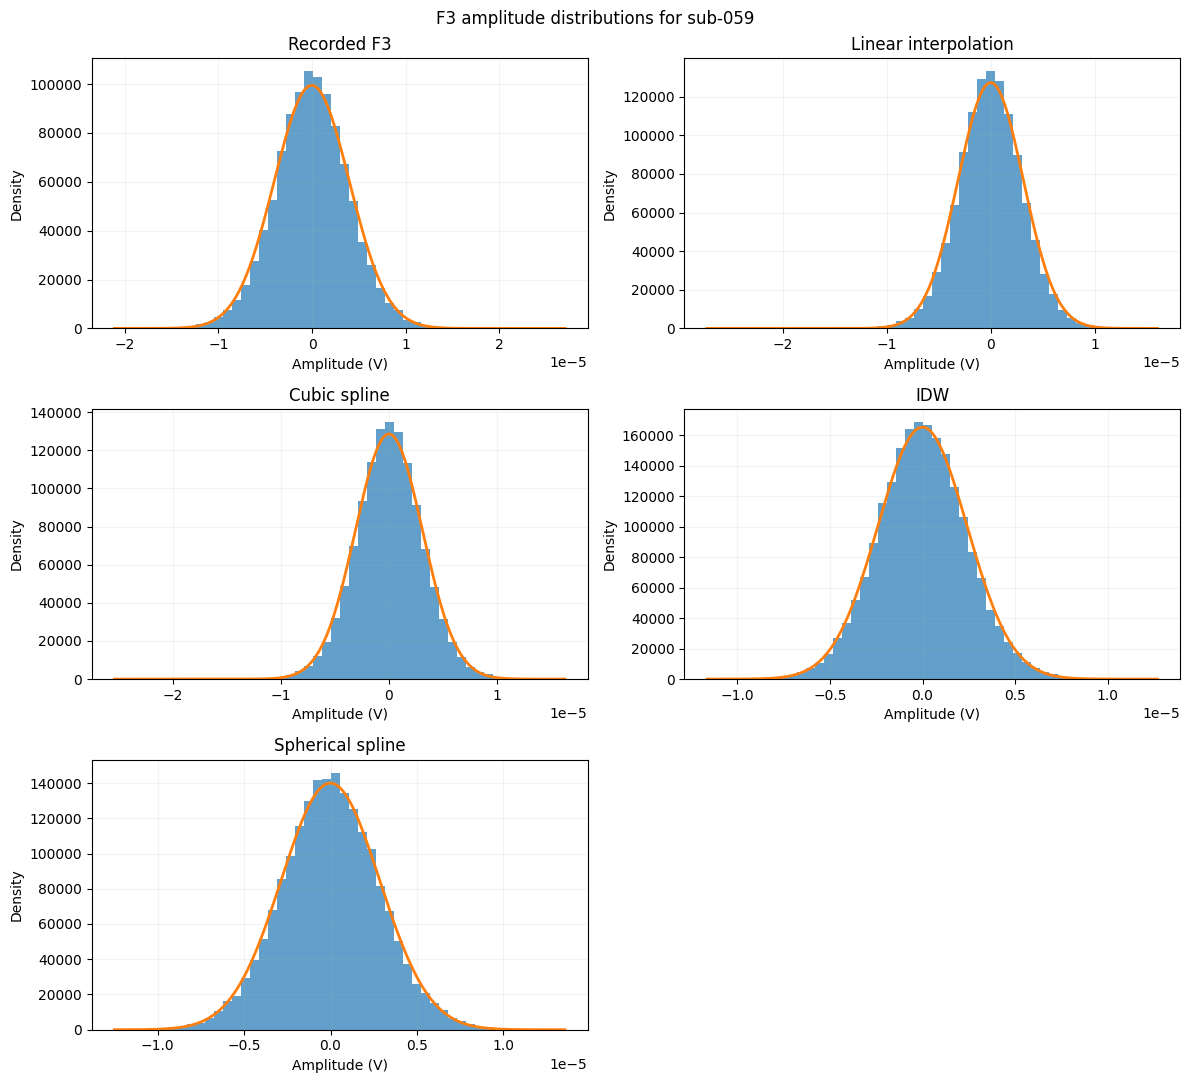

In [26]:
def sample_signal(signal, max_size=max_samples, seed=random_state):
    """Return a repeatable random sample of finite EEG amplitudes."""
    signal = np.asarray(signal)
    signal = signal[np.isfinite(signal)]
    if len(signal) > max_size:
        return np.random.default_rng(seed).choice(signal, size=max_size, replace=False)
    return signal


def plot_subject_histograms(subject_code):
    """Compare amplitude distributions across all five signals."""
    signals, _ = load_subject_signals(subject_code)
    fig, axes = plt.subplots(3, 2, figsize=(12, 11))
    axes = axes.ravel()
    for ax, (method, signal) in zip(axes, signals.items()):
        sample = sample_signal(signal)
        ax.hist(sample, bins=50, density=True, alpha=0.7)
        std = np.std(sample)
        if std > 0:
            x = np.linspace(np.min(sample), np.max(sample), 400)
            ax.plot(x, norm.pdf(x, np.mean(sample), std), linewidth=2)
        ax.set_title(method_names[method])
        ax.set_xlabel("Amplitude (V)")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.15)
    for ax in axes[len(signals):]:
        ax.axis("off")
    fig.suptitle(f"F3 amplitude distributions for {subject_code}")
    fig.tight_layout()
    plt.show()


if subject_has_all_signals(histogram_subject):
    plot_subject_histograms(histogram_subject)
else:
    print(f"Skipping amplitude histograms: signal caches for {histogram_subject} are incomplete.")

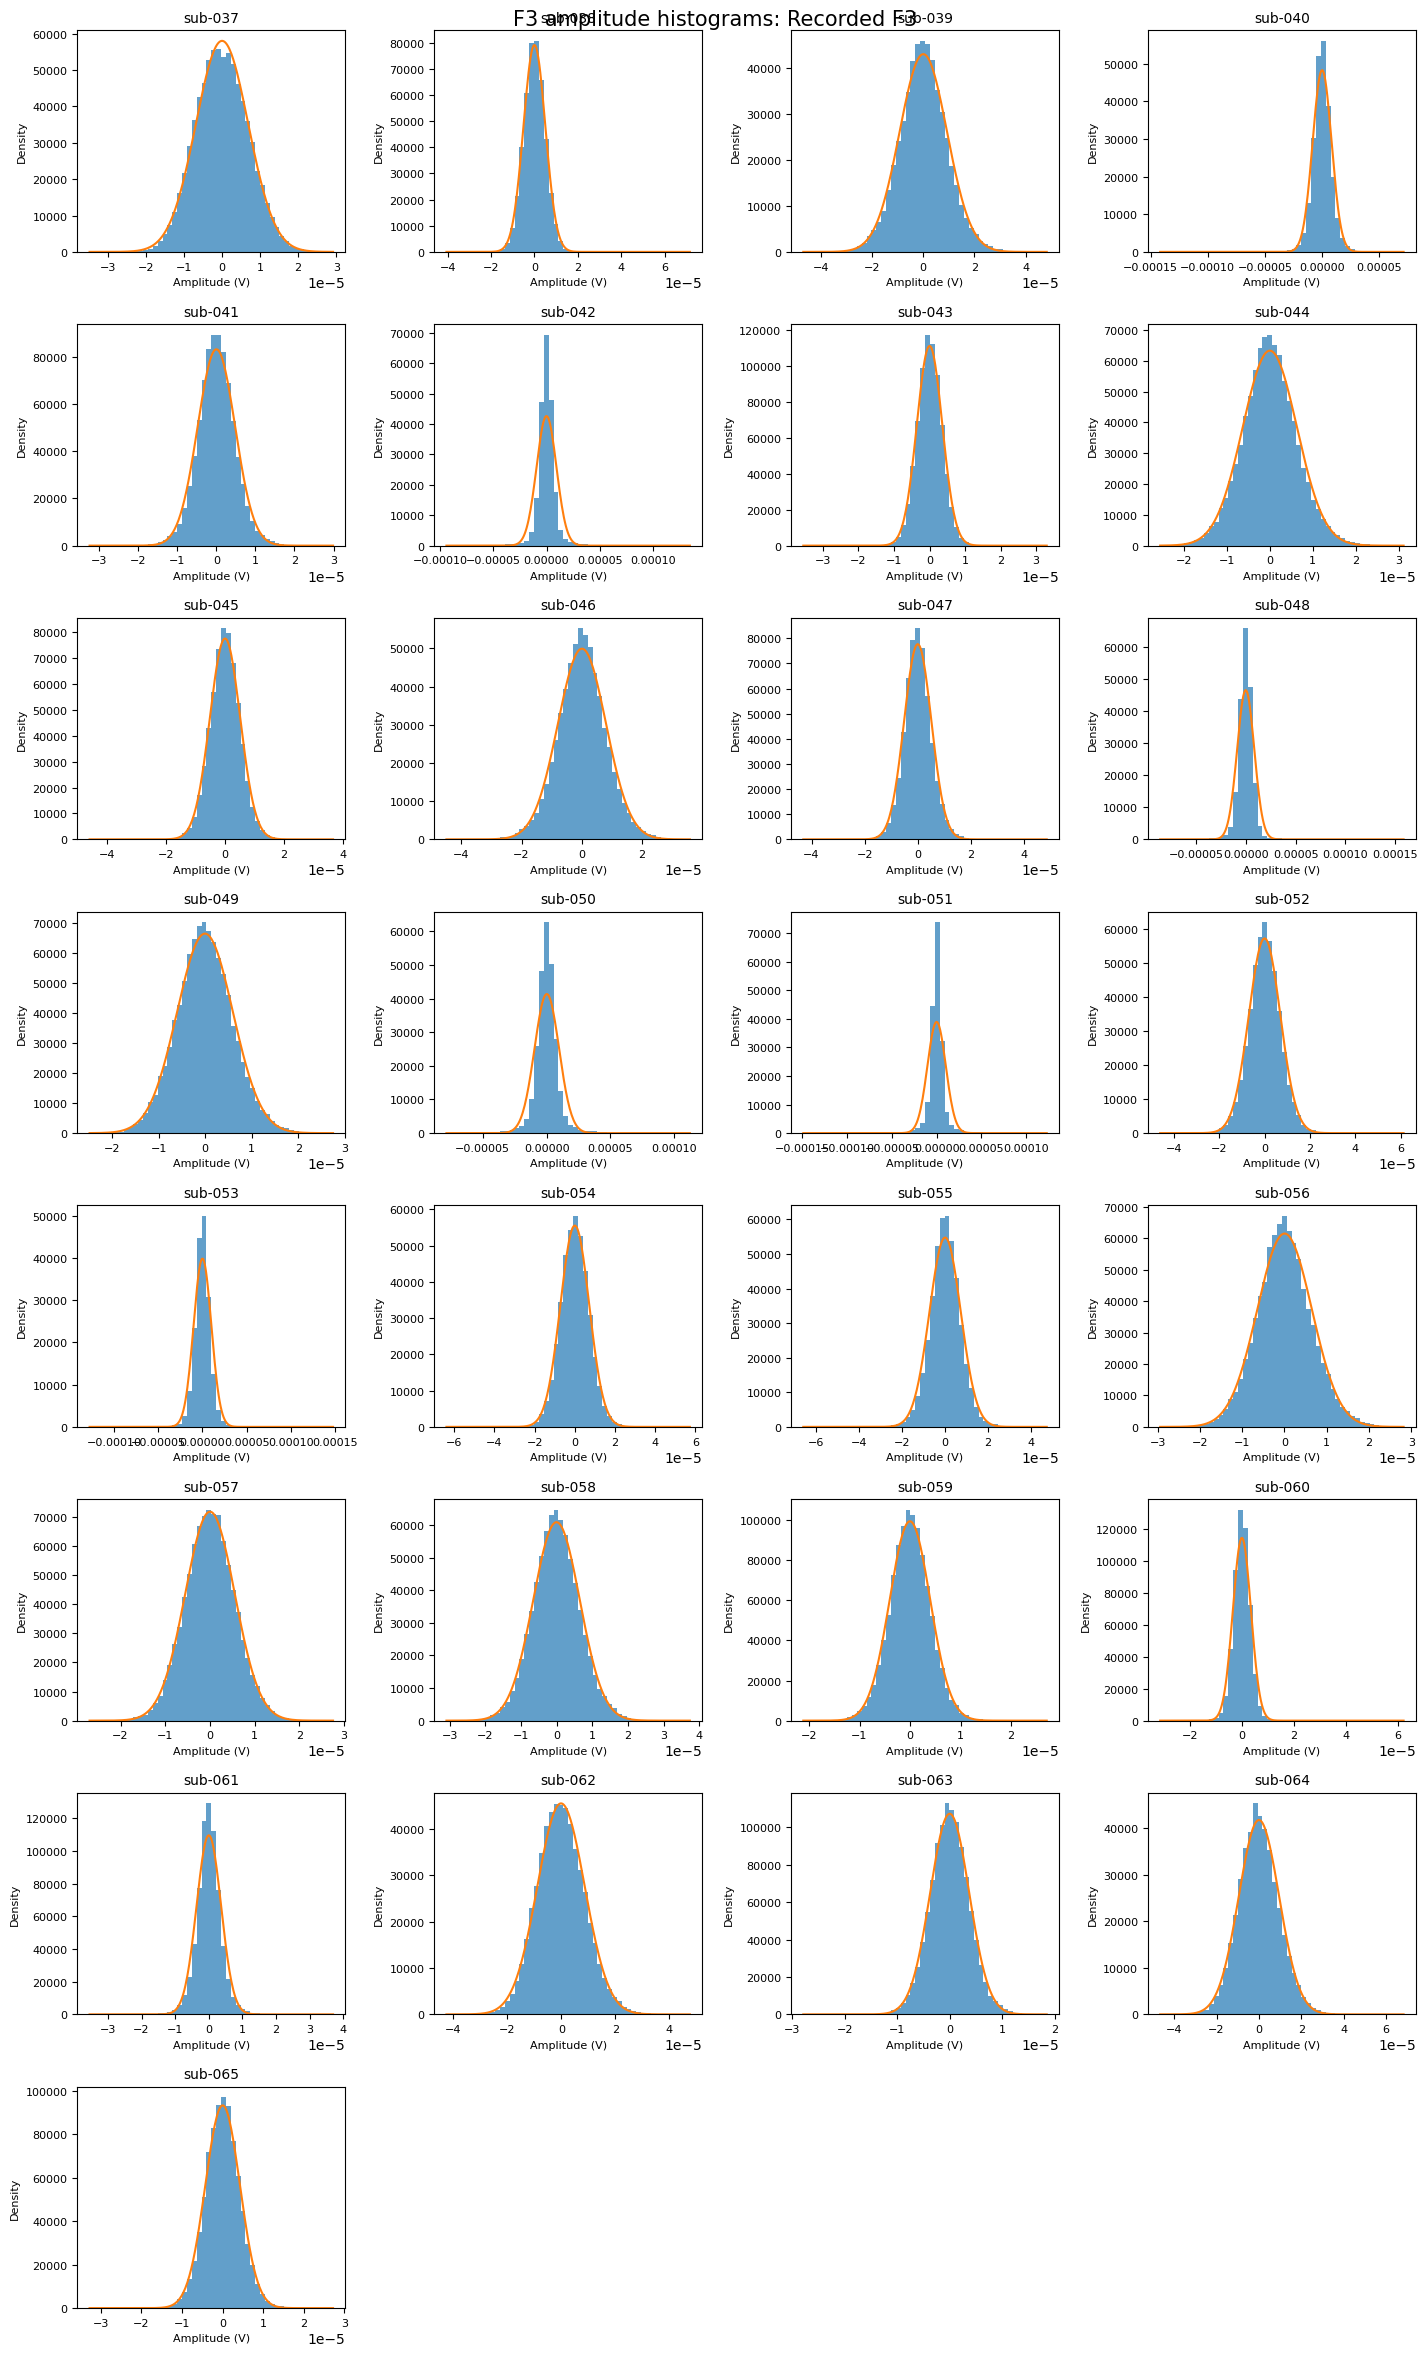

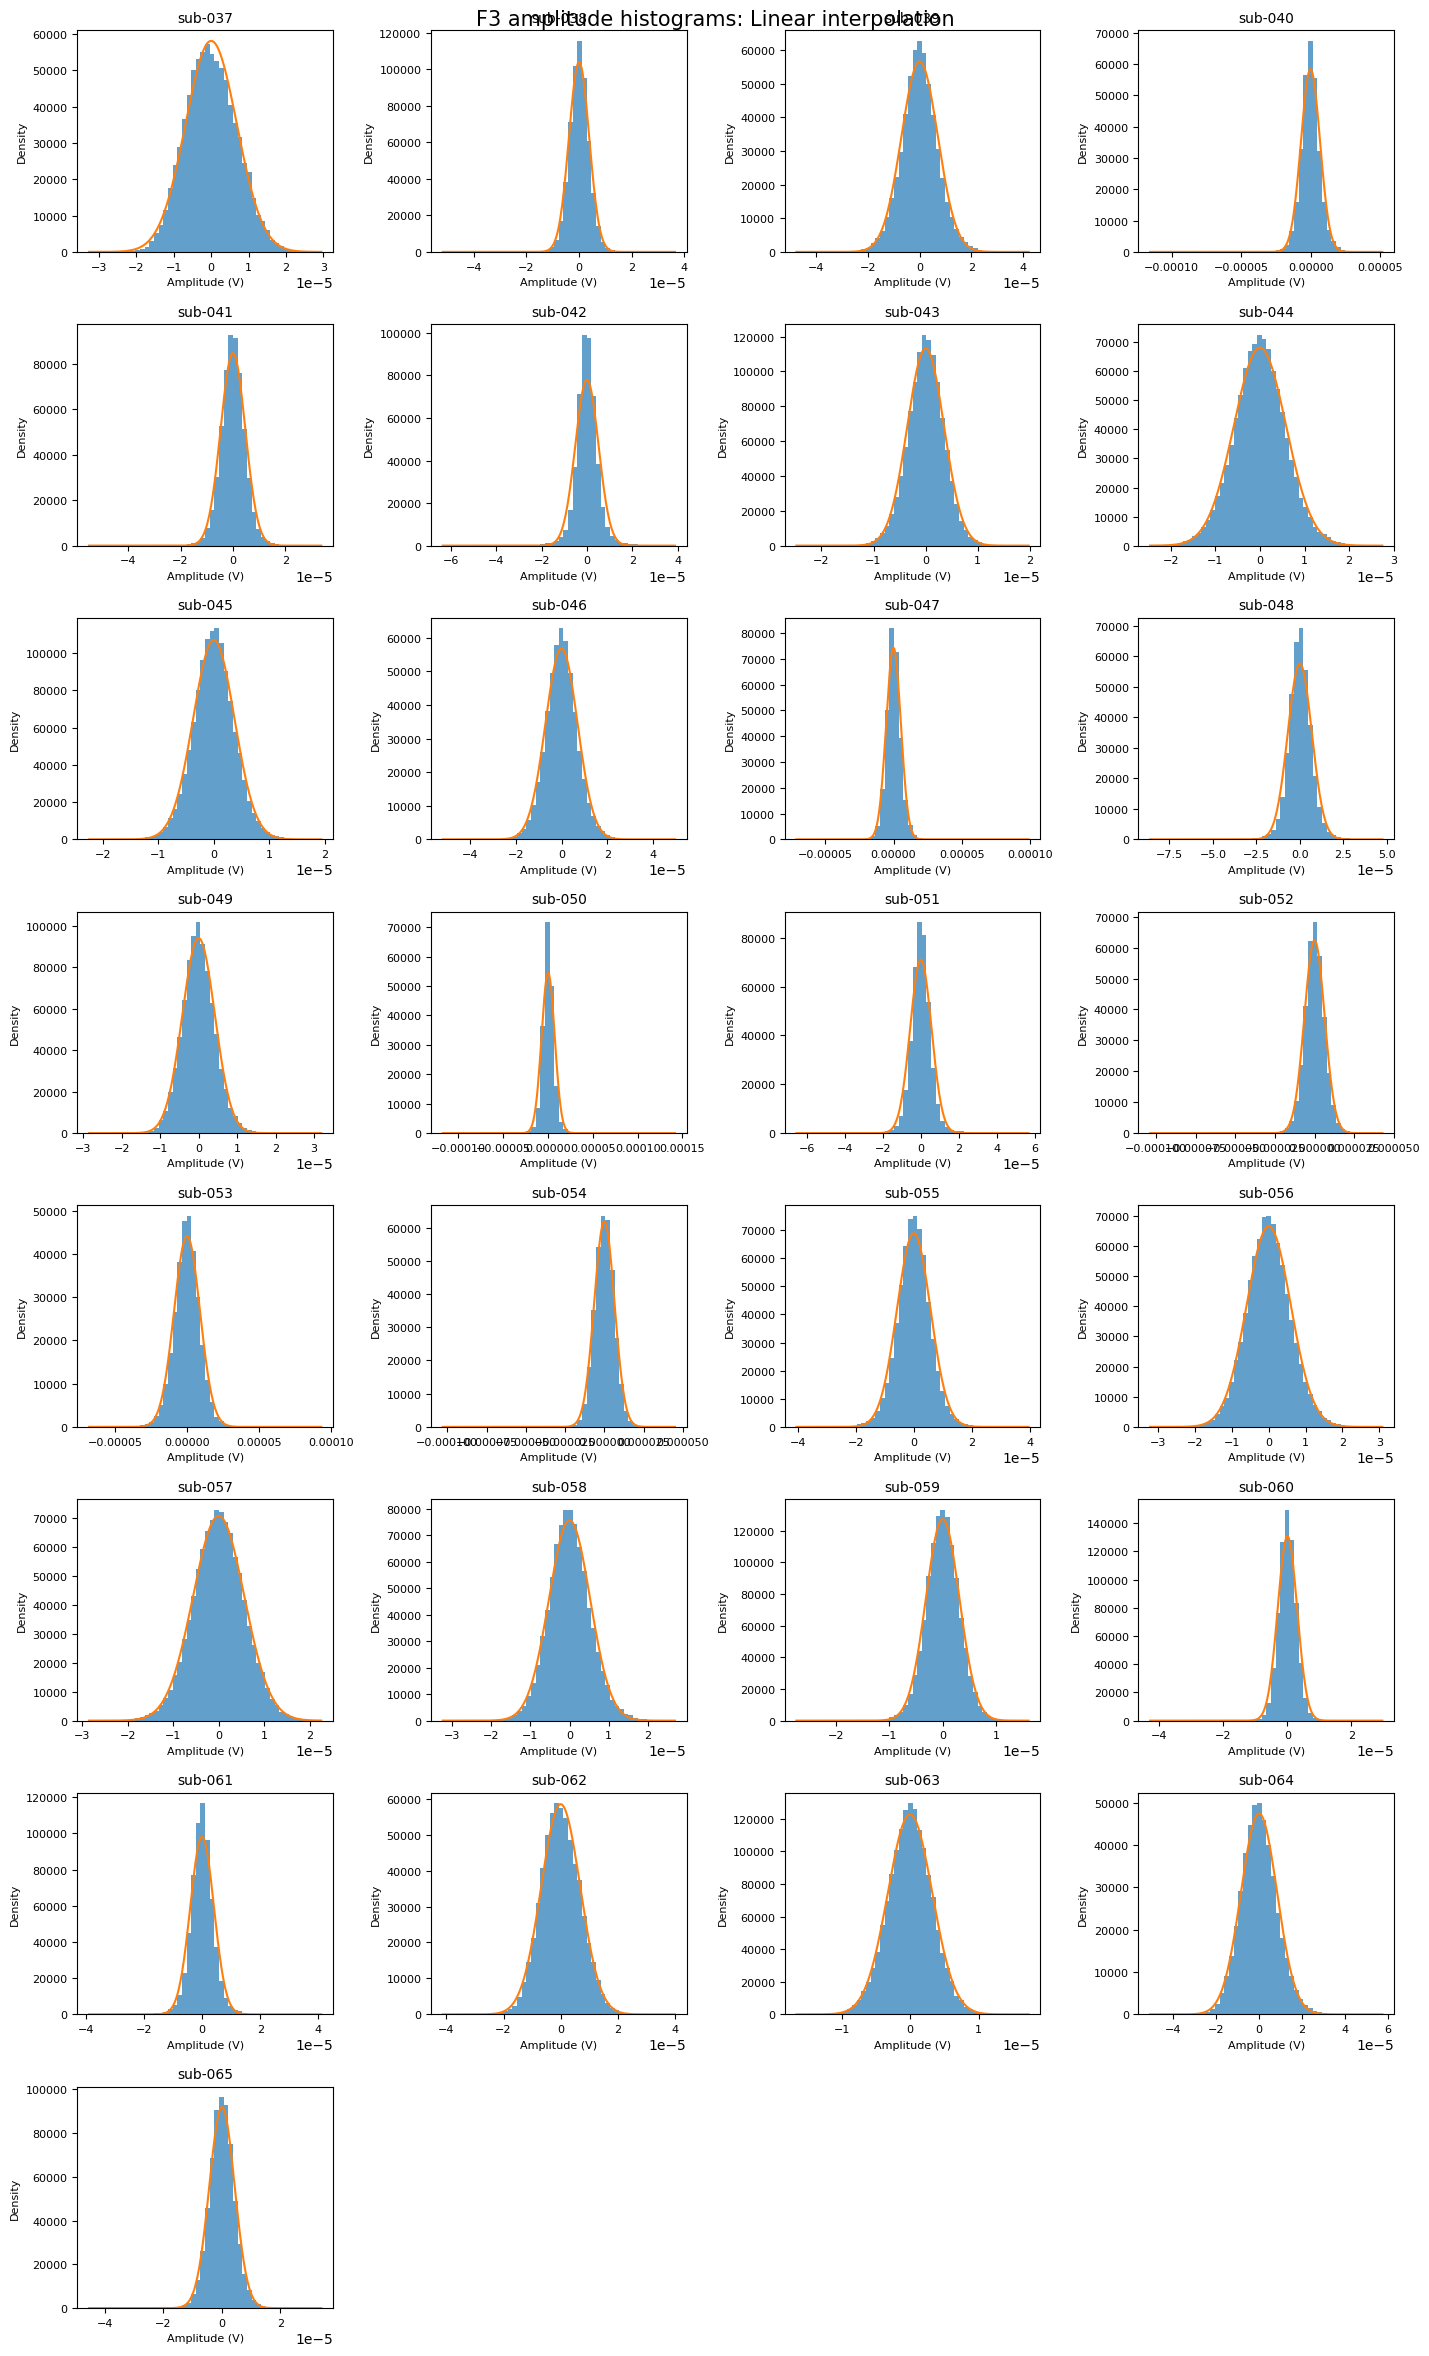

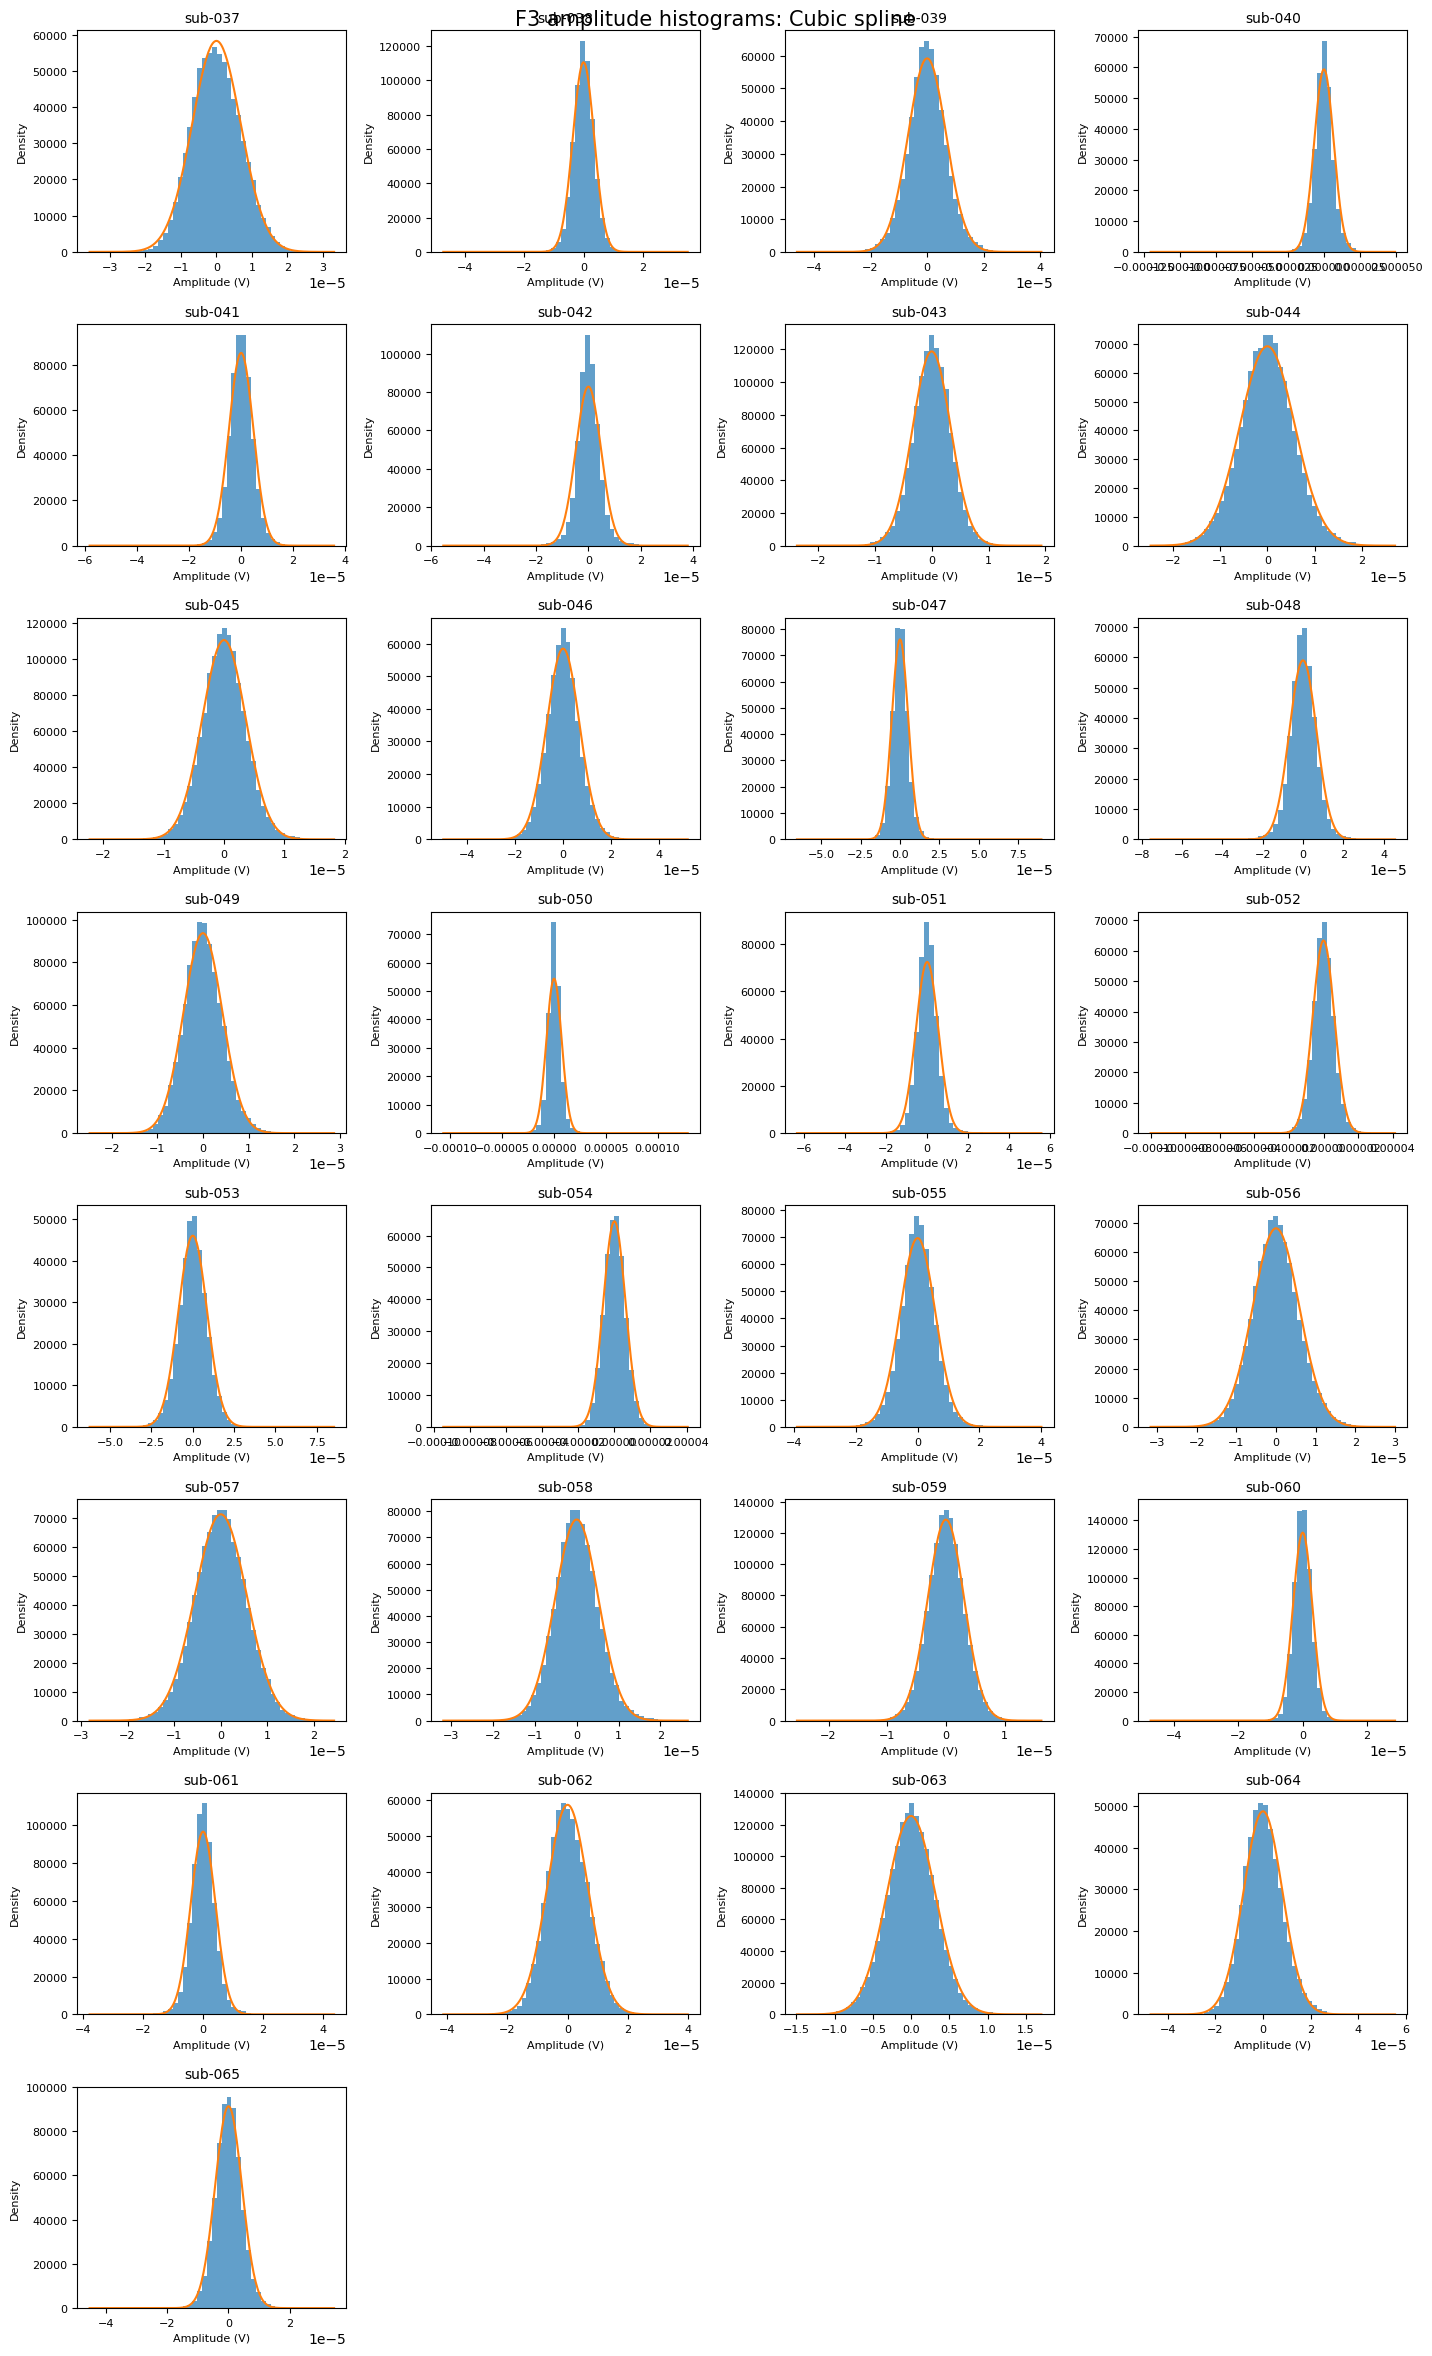

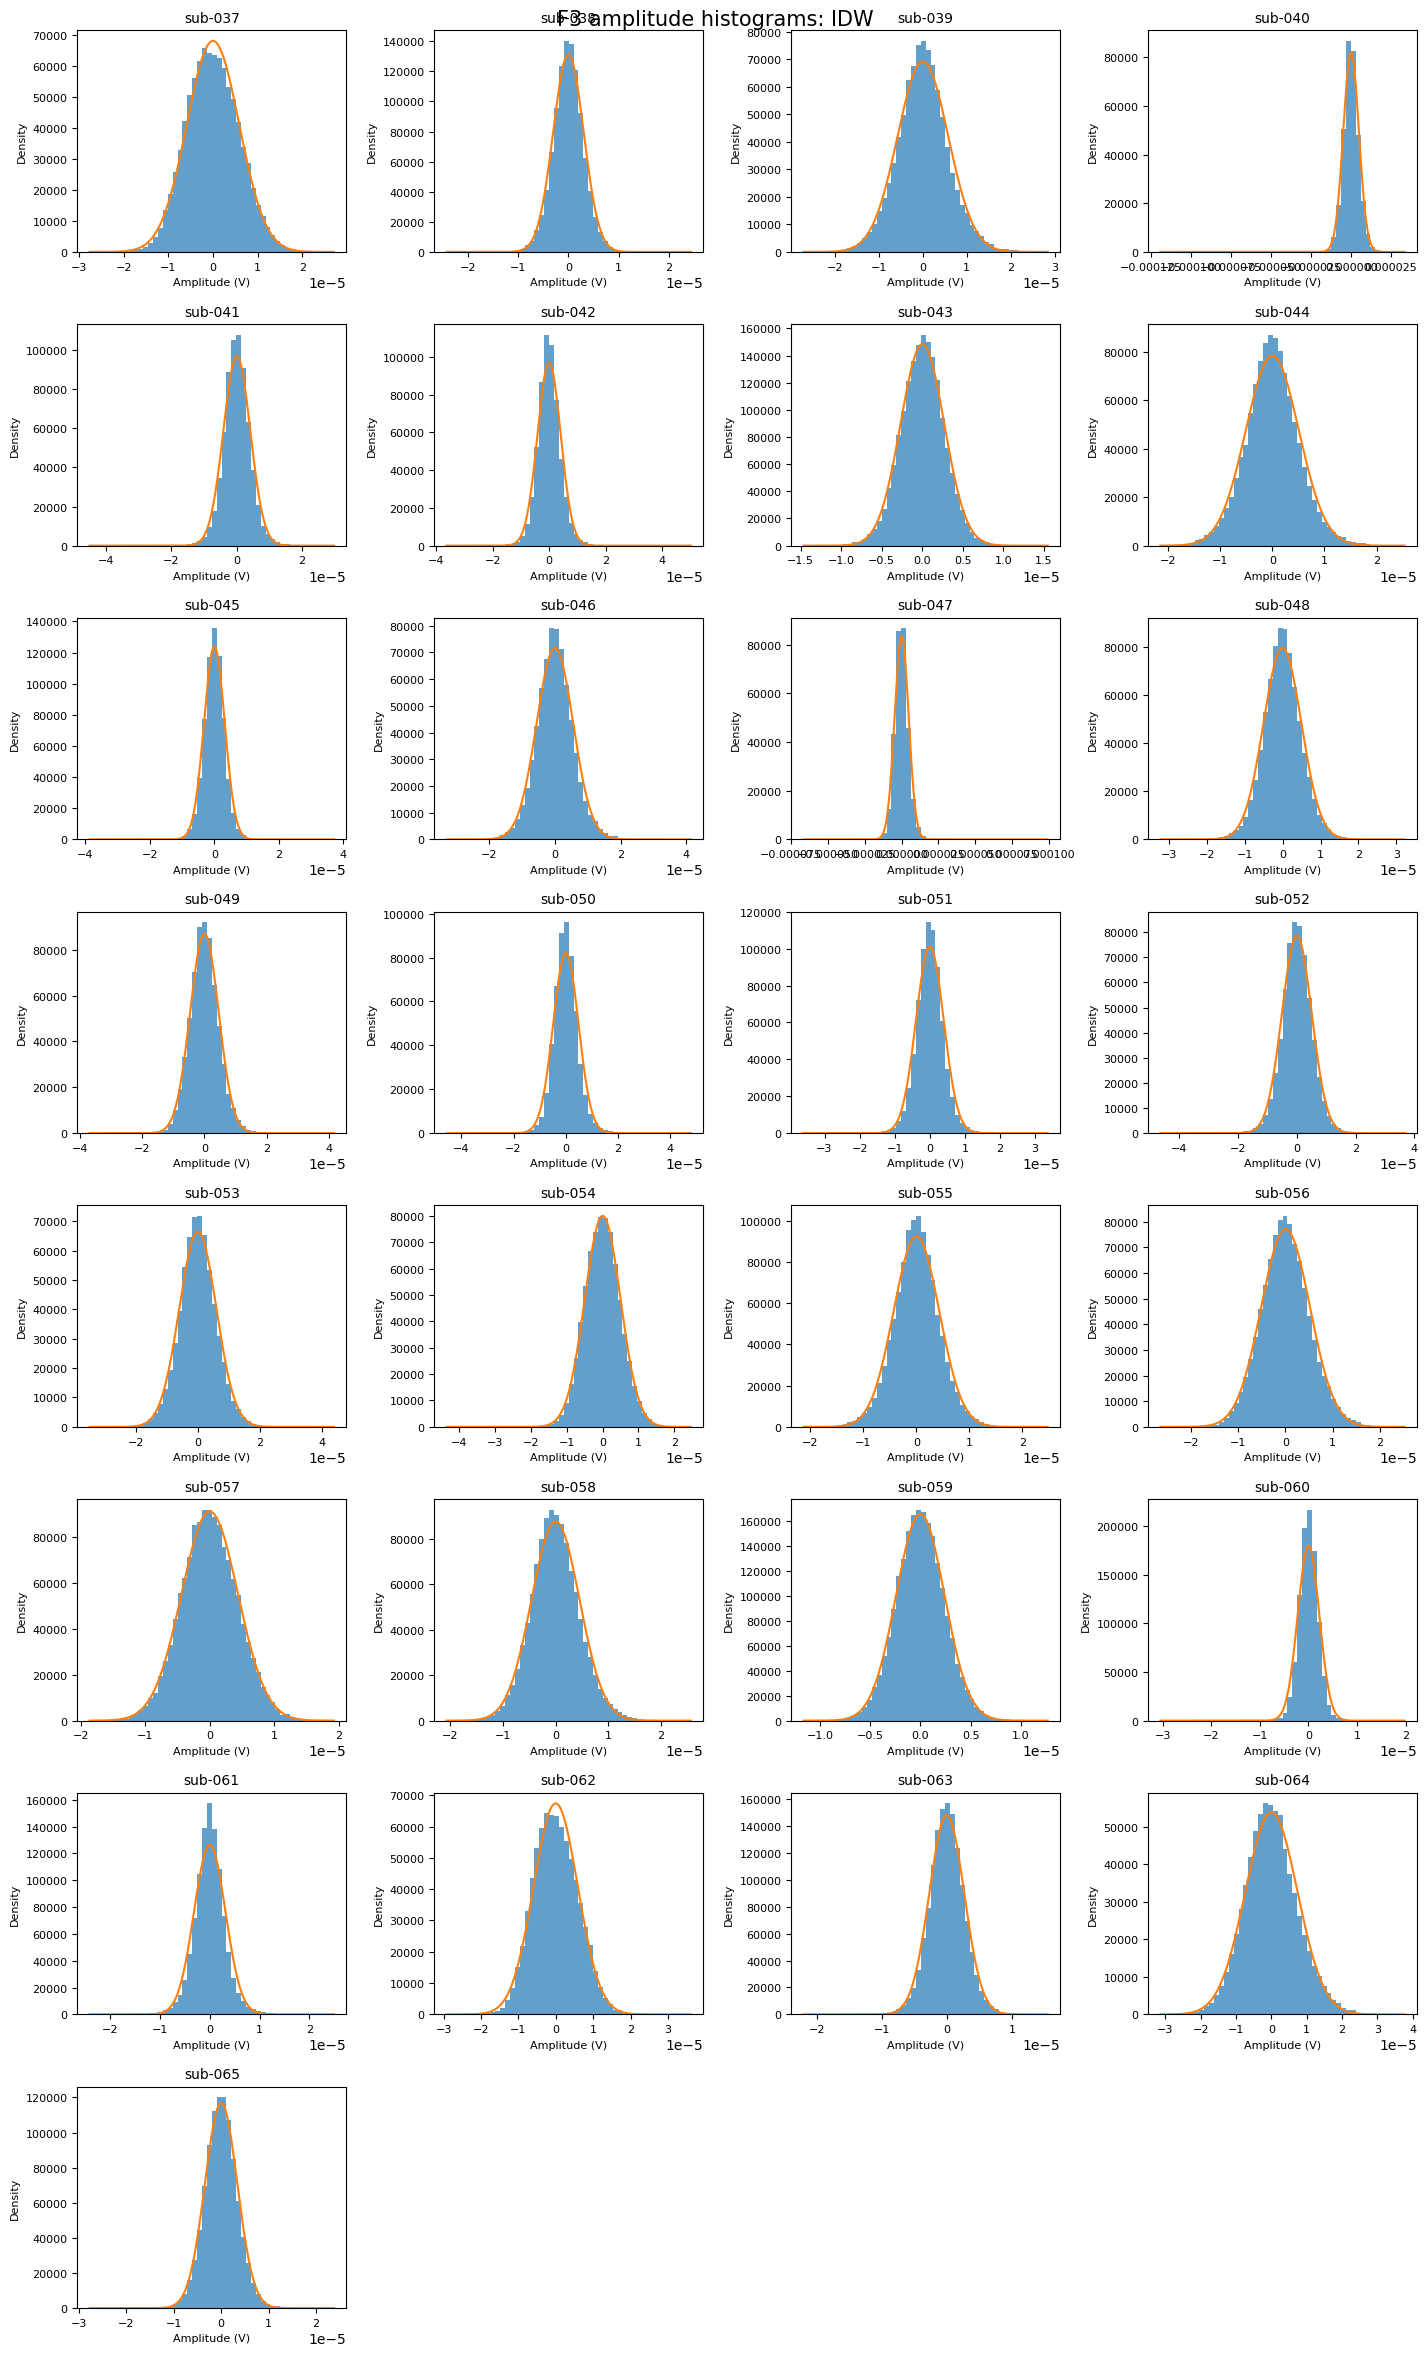

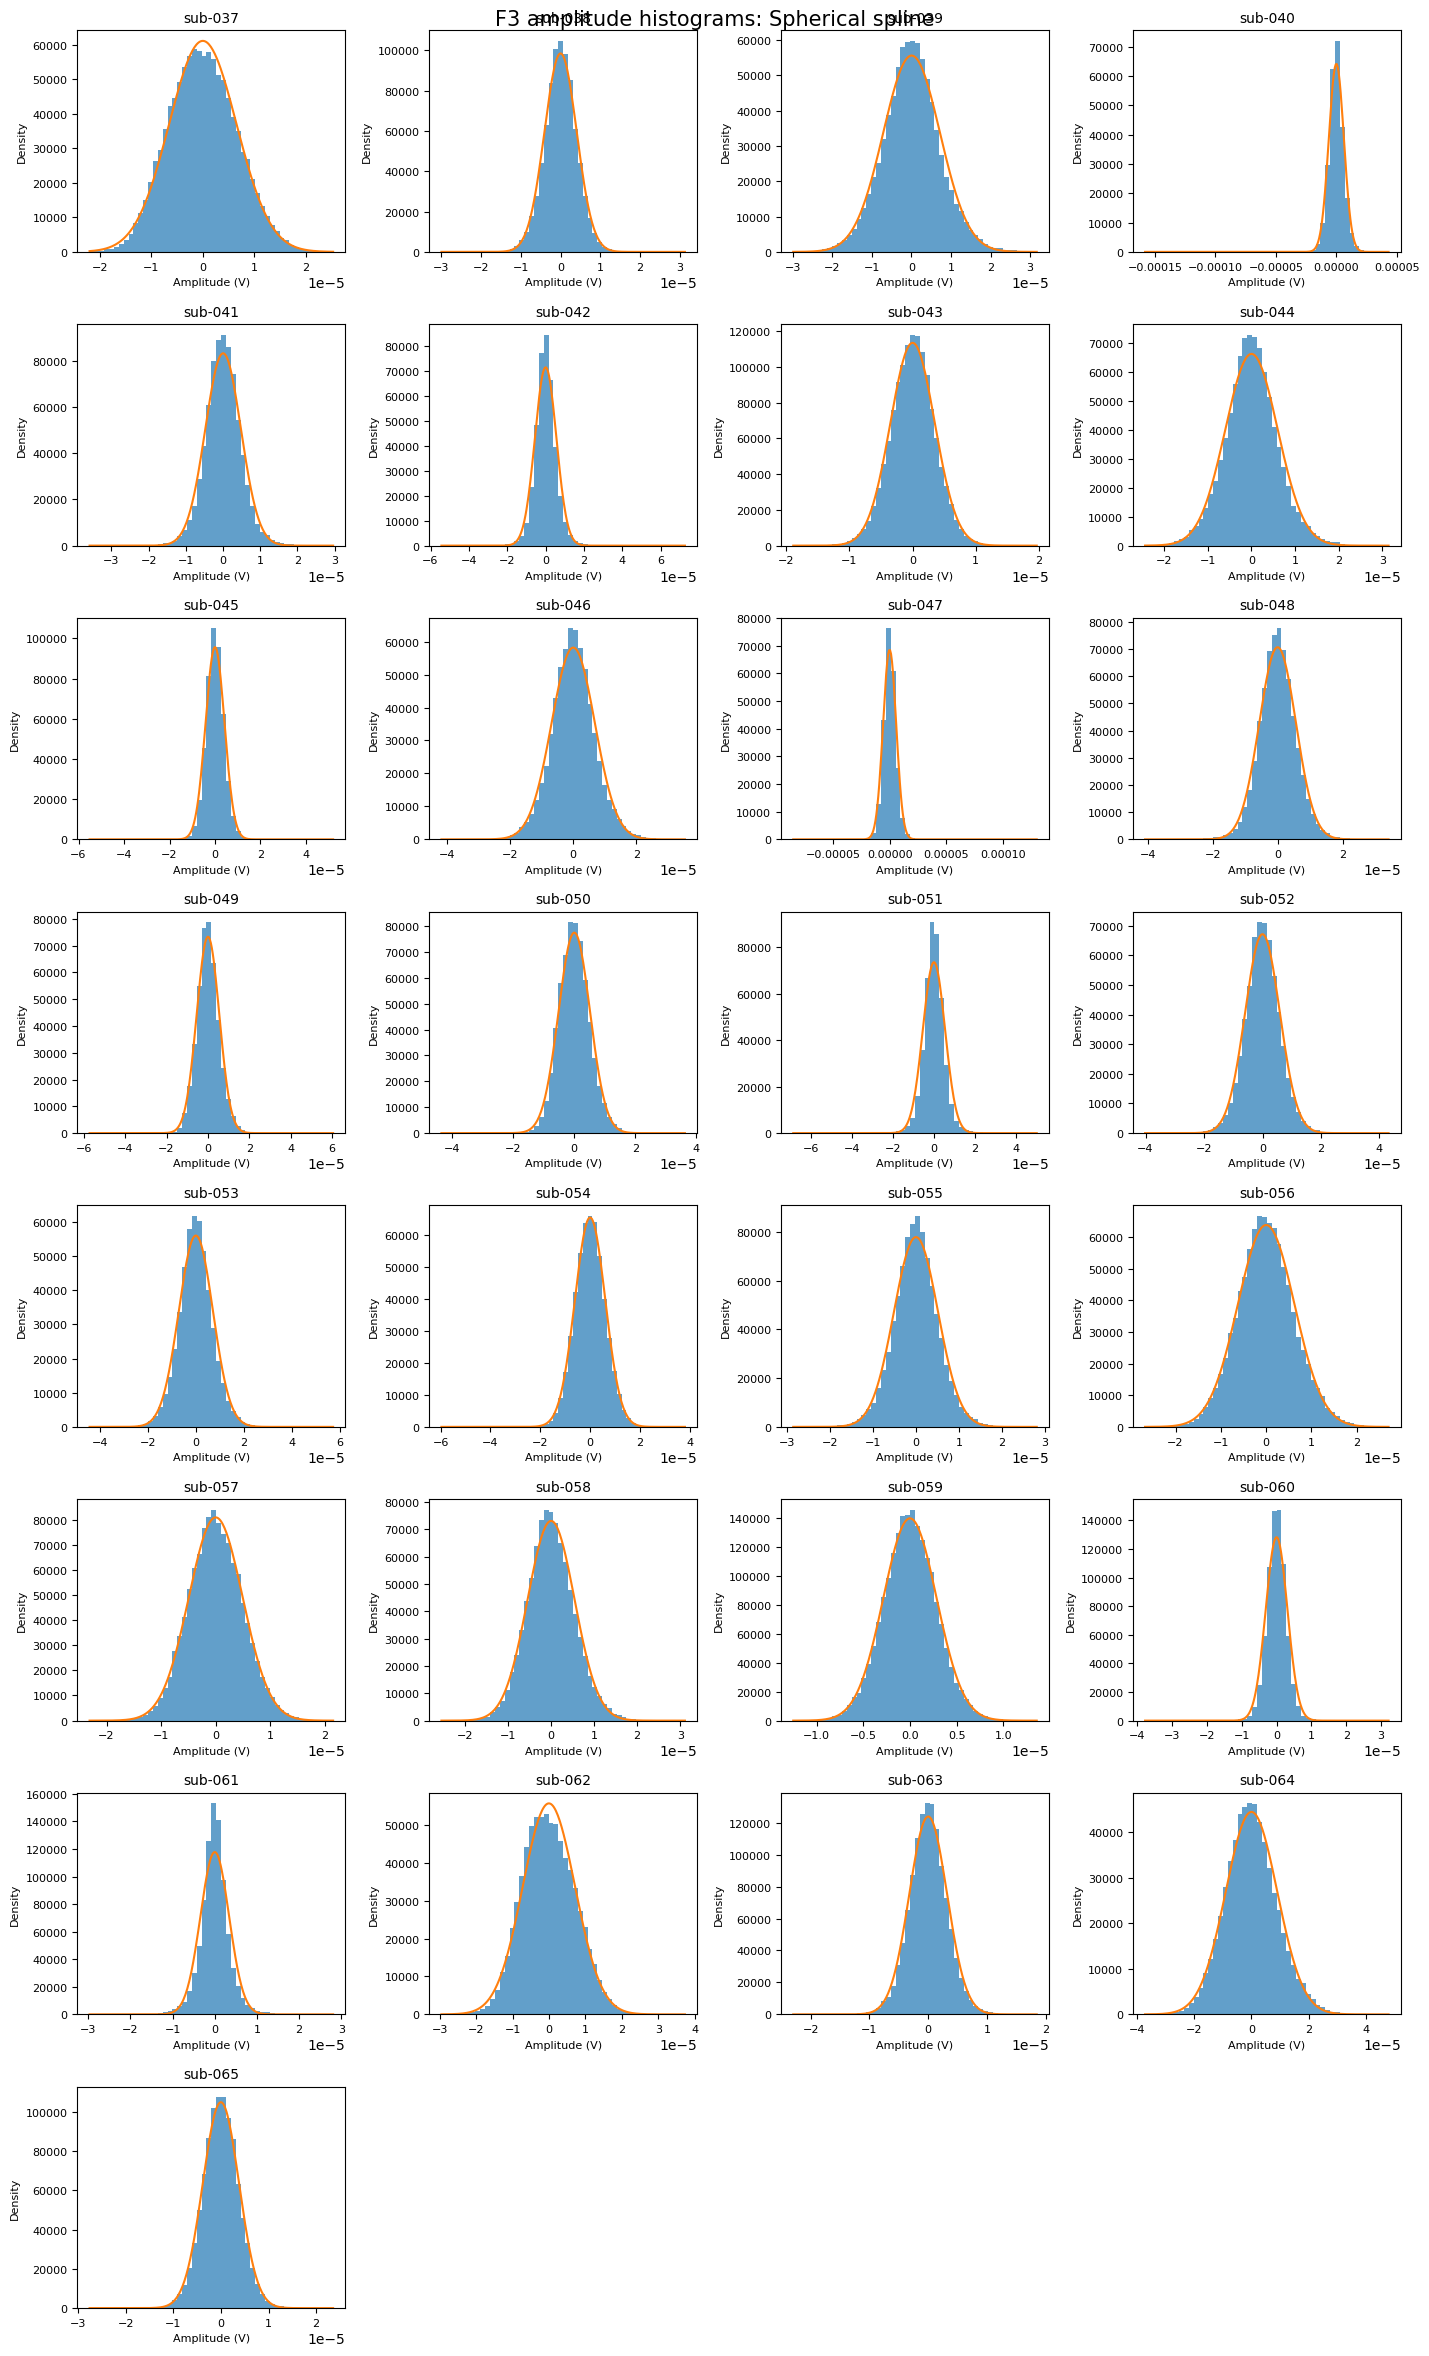

In [27]:
def plot_histogram_grid(method, subject_codes=subjects, n_cols=4):
    """Plot amplitude histograms for all available subjects for one method."""
    n_rows = ceil(len(subject_codes) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3 * n_rows))
    axes = np.asarray(axes).ravel()
    for ax, subject_code in zip(axes, subject_codes):
        path = cache_path(subject_code, method)
        if not path.exists():
            ax.text(0.5, 0.5, "Signal not available", ha="center", va="center")
            ax.set_title(subject_code)
            ax.axis("off")
            continue
        with np.load(path, allow_pickle=False) as cached:
            sample = sample_signal(cached["signal"])
        ax.hist(sample, bins=50, density=True, alpha=0.7)
        std = np.std(sample)
        if std > 0:
            x = np.linspace(np.min(sample), np.max(sample), 250)
            ax.plot(x, norm.pdf(x, np.mean(sample), std), linewidth=1.5)
        ax.set_title(subject_code, fontsize=10)
        ax.set_xlabel("Amplitude (V)", fontsize=8)
        ax.set_ylabel("Density", fontsize=8)
        ax.tick_params(labelsize=8)
    for ax in axes[len(subject_codes):]:
        ax.axis("off")
    fig.suptitle(f"F3 amplitude histograms: {method_names[method]}", fontsize=15)
    fig.tight_layout()
    plt.show()


if plot_all_histogram_grids:
    for method in method_names:
        plot_histogram_grid(method)
else:
    print("Full histogram grids are disabled. Set plot_all_histogram_grids = True to enable them.")

### Log–log PSD and power-law slope
The original notebook estimated a linear slope between log10(frequency) and log10(PSD) in the 1–45 Hz band. The same regression is applied here to already saved signals. The fitted slope describes an overall spectral trend, not necessarily a physical power law over the entire band.

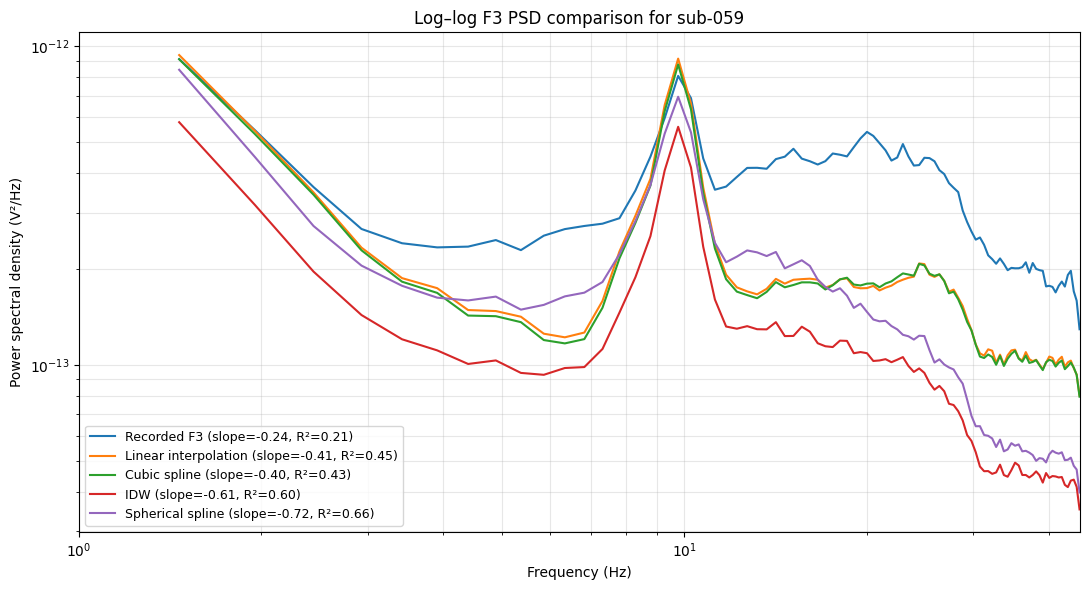

,Method,Slope,R²,p-value,Standard error
0,Recorded F3,-0.242727,0.207754,6.349268e-06,0.050528
1,Linear interpolation,-0.412353,0.447288,5.852763e-13,0.048863
2,Cubic spline,-0.401015,0.429355,2.431940e-12,0.049283
3,IDW,-0.609739,0.604475,2.043265e-19,0.052578
4,Spherical spline,-0.723453,0.661672,2.025619e-22,0.055146


In [28]:
def compute_loglog_psd(signal, fs, freq_min=1, freq_max=45):
    """Estimate a log–log spectral slope using Welch PSD and linear regression."""
    frequencies, psd = welch(signal, fs=fs, nperseg=nperseg)
    mask = (frequencies >= freq_min) & (frequencies <= freq_max) & (psd > 0)
    fit_frequencies = frequencies[mask]
    fit_psd = psd[mask]
    if len(fit_frequencies) < 2:
        raise ValueError("Not enough positive PSD values for log–log regression.")

    fit = linregress(np.log10(fit_frequencies), np.log10(fit_psd))
    return {
        "frequencies": fit_frequencies,
        "psd": fit_psd,
        "fitted_psd": 10 ** (fit.intercept + fit.slope * np.log10(fit_frequencies)),
        "slope": fit.slope,
        "r_squared": fit.rvalue ** 2,
        "p_value": fit.pvalue,
        "std_err": fit.stderr,
    }


if subject_has_all_signals(power_law_subject):
    saved_signals, fs = load_subject_signals(power_law_subject)
    power_law_results = {
        method: compute_loglog_psd(signal, fs)
        for method, signal in saved_signals.items()
    }

    plt.figure(figsize=(11, 6))
    for method, values in power_law_results.items():
        plt.loglog(
            values["frequencies"], values["psd"],
            label=f"{method_names[method]} (slope={values['slope']:.2f}, R²={values['r_squared']:.2f})",
        )
    plt.xlim(1, 45)
    plt.title(f"Log–log F3 PSD comparison for {power_law_subject}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density (V²/Hz)")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    power_law_df = pd.DataFrame([
        {
            "Method": method_names[method],
            "Slope": values["slope"],
            "R²": values["r_squared"],
            "p-value": values["p_value"],
            "Standard error": values["std_err"],
        }
        for method, values in power_law_results.items()
    ])
    display(power_law_df)
    power_law_df.to_csv(
        analysis_dir / f"F3_power_law_{power_law_subject}.csv", index=False, encoding="utf-8-sig"
    )
else:
    print(f"Skipping power-law analysis: signal caches for {power_law_subject} are incomplete.")

### Reproducibility
Only the four separate method notebooks perform interpolation. Once they have been run with the saved-signal additions, this notebook can be executed repeatedly without reconstructing F3. The spectral plots, amplitude histograms, and PSD slope estimates are calculated from those cached signals.

The data needed to regenerate these plots (cleaned EEG recordings and reconstructed signal caches) should be stored locally and excluded from GitHub. The metric CSV files can be retained separately if their use and sharing are permitted.